## Initial Data Inspection and Audit

In [42]:
import pandas as pd

In [43]:
df = pd.read_csv("CT4101 Portfolio/Data/applications.csv")
df.shape
df.head()
df.sample(5, random_state=42)
df.info()
df.describe(include="all").T
df.isna().mean().sort_values(ascending=False)
df.nunique().sort_values()
df.duplicated().sum() #number duplicate values

C:\Users\Ruth\AppData\Local\Temp\ipykernel_3568\2606706245.py:1: DtypeWarning: Columns (7,9,10,18,19,40,42,43,44,45,46,47,48,49,50,51,53) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("CT4101 Portfolio/Data/applications.csv")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43619 entries, 0 to 43618
Data columns (total 64 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   application_reference_no                                  43619 non-null  object 
 1   application_type                                          43619 non-null  object 
 2   local_authority                                           43619 non-null  object 
 3   submission_no                                             43619 non-null  int64  
 4   submission_date                                           43619 non-null  object 
 5   date_permission_was_granted                               23329 non-null  object 
 6   planning_permission_reference_no                          29947 non-null  object 
 7   seven_days_submission_no                                  6714 non-null   object 
 8   classification_o

np.int64(757)

Inspecting the data with pandas

In [44]:
duplicates = df[df.duplicated(keep=False)]

duplicates.shape
# number rows invloved in exact duplication

(1448, 64)

In [45]:
duplicates.head(15)

,application_reference_no,application_type,local_authority,submission_no,submission_date,date_permission_was_granted,planning_permission_reference_no,seven_days_submission_no,classification_of_works_or_building,development_description,...,decision_by_an_bord_pleanala,appeal_type,decision_type,applicant_name,applicant_address_line_1,applicant_address_line_2,applicant_town,applicant_county,applicant_postcode,is_the_applicant_the_owner_or_leaseholder
11,DAC2105166OY,disability_access_certificate_application_dac,Offaly County Council,4002009,2021-06-25,2021-03-12,PL2/ 21/13,NaN,^construction_new_building^,Demolition of existing prefabs to the South Ea...,...,NaN,NaN,granted,Board Of Management,NaN,NaN,NaN,NaN,NaN,owner
12,DAC2105166OY,disability_access_certificate_application_dac,Offaly County Council,4002009,2021-06-25,2021-03-12,PL2/ 21/13,NaN,^construction_new_building^,Demolition of existing prefabs to the South Ea...,...,NaN,NaN,granted,Board Of Management,NaN,NaN,NaN,NaN,NaN,owner
28,DAC2201991OY,disability_access_certificate_application_dac,Offaly County Council,4004557,2022-04-15,2021-05-10,20450,NaN,^construction_new_building^,"Apartment Development, Block A, at Tullamore, ...",...,NaN,NaN,granted,eamonn power,"12th Floor, Riverpoint,",Lower Mallow Street,Limerick,limerick,V94WC6A,owner
29,DAC2201991OY,disability_access_certificate_application_dac,Offaly County Council,4004557,2022-04-15,2021-05-10,20450,NaN,^construction_new_building^,"Apartment Development, Block A, at Tullamore, ...",...,NaN,NaN,granted,eamonn power,"12th Floor, Riverpoint,",Lower Mallow Street,Limerick,limerick,V94WC6A,owner
49,DAC2101509LS,disability_access_certificate_application_dac,Laois County Council,4000869,2021-01-11,2020-07-20,2060,NaN,"^material_alterations^,^extension_to_a_buildin...","Proposed extension, material alterations and c...",...,NaN,NaN,granted_with_conditions,David Walsh-Kemmis,Ballykilcavan\nStradbally,NaN,Portlaoise,laois,R32 PY89,owner
50,DAC2101509LS,disability_access_certificate_application_dac,Laois County Council,4000869,2021-01-11,2020-07-20,2060,NaN,"^material_alterations^,^extension_to_a_buildin...","Proposed extension, material alterations and c...",...,NaN,NaN,granted_with_conditions,David Walsh-Kemmis,Ballykilcavan\nStradbally,NaN,Portlaoise,laois,R32 PY89,owner
75,DAC2202813OY,disability_access_certificate_application_dac,Offaly County Council,4004685,2022-05-20,2020-10-22,19474,NaN,^material_change_of_use^,Material change of use from existing coach hou...,...,NaN,NaN,granted,Bryan Bean,210 w Amelia Ave,Unit A,Tampa,NaN,33602,owner
76,DAC2202813OY,disability_access_certificate_application_dac,Offaly County Council,4004685,2022-05-20,2020-10-22,19474,NaN,^material_change_of_use^,Material change of use from existing coach hou...,...,NaN,NaN,granted,Bryan Bean,210 w Amelia Ave,Unit A,Tampa,NaN,33602,owner
113,DAC2000107SO,disability_access_certificate_application_dac,Sligo County Council,4000032,2020-07-23,2020-06-11,PL 20/59,NaN,^material_alterations^,Material alterations to combine a common room ...,...,NaN,NaN,granted,Kevin Doran,St Mary's,Temple Street,Sligo,sligo,F91 KTX2,owner
114,DAC2000107SO,disability_access_certificate_application_dac,Sligo County Council,4000032,2020-07-23,2020-06-11,PL 20/59,NaN,^material_alterations^,Material alterations to combine a common room ...,...,NaN,NaN,granted,Kevin Doran,St Mary's,Temple Street,Sligo,sligo,F91 KTX2,owner


In [46]:
df[["submission_date", "date_of_decision"]].head(10) #checking variables needed to calculate target variable

,submission_date,date_of_decision
0,2023-03-28,2023-05-16
1,2023-04-25,2023-05-16
2,2025-07-31,2025-09-25
3,2023-03-24,2023-05-15
4,2023-03-24,2023-05-15
5,2020-09-24,2020-11-03
6,2022-10-19,2023-05-16
7,2023-03-29,2023-05-16
8,2023-07-28,2023-09-26
9,2025-07-31,2025-09-25


In [47]:
df["application_type"].value_counts(dropna=False) 

application_type
fire_safety_certificate_application_fsc          20244
disability_access_certificate_application_dac    16649
revised_fire_safety_certificate_fsc_rv            2724
regularisation_certificate_application_fsc_rg     1953
revised_disability_access_certificate_dac_rv      1436
dispensations                                      512
relaxations                                        101
Name: count, dtype: int64

In [48]:
df["decision_type"].value_counts(dropna=False)

decision_type
granted_with_conditions    30865
granted                    12117
refused                      592
NaN                           45
Name: count, dtype: int64

Contains missing values


In [49]:
df["application_reference_no"].nunique()

42714

In [50]:
df["submission_no"].value_counts().sort_index()

submission_no
3000025    1
3000031    1
3000032    1
3000033    1
3000039    1
          ..
5001430    1
5001433    1
5001438    2
5001444    1
5001469    1
Name: count, Length: 42714, dtype: int64

In [51]:
counts = df["application_reference_no"].value_counts()

repeated_refs = counts[counts > 1]

repeated_refs.head(20)

application_reference_no
DAC2300032CE        15
FSC2101459CE         6
DAC2510692KE         5
DAC2618312DC         5
DAC2304827DR         4
DAC2407125OY         4
FSC2000877DL/7DN     4
FSC2303081LH/7DN     4
FSC2404611SD         4
FSC2104840MH         4
FSC2200596DL/7DN     4
FSC2205032SD/7DN     4
DRV2102028DC         4
FRV2000522LL         4
DAC2401874CY         3
DAC2202202TT         3
DAC2514907KK         3
FSC2000802WD         3
DAC2204435KE         3
DAC2517730RN         3
Name: count, dtype: int64

In [52]:
repeated_refs.shape

(805,)

In [53]:
app = df[df["application_reference_no"] == "DAC2300032CE"]

app.drop_duplicates().shape

(8, 64)

In [54]:
app_unique = app.drop_duplicates()

app_unique.nunique(dropna=False)

application_reference_no                     1
application_type                             1
local_authority                              1
submission_no                                1
submission_date                              1
                                            ..
applicant_address_line_2                     1
applicant_town                               1
applicant_county                             1
applicant_postcode                           1
is_the_applicant_the_owner_or_leaseholder    1
Length: 64, dtype: int64

In [55]:
app_unique.nunique(dropna=False)[
    app_unique.nunique(dropna=False) > 1
]

decision_by_an_bord_pleanala    2
appeal_type                     3
decision_type                   2
dtype: int64

In [56]:
app_unique[[
    "decision_by_an_bord_pleanala",
    "appeal_type",
    "decision_type",
    "date_of_decision"
]]

,decision_by_an_bord_pleanala,appeal_type,decision_type,date_of_decision
5991,It is the decision of an Bord Pleanla that an ...,refused_after_appeal,granted_with_conditions,2023-03-14
5992,It is the decision of an Bord Pleanla that an ...,refused_after_appeal,NaN,2023-03-14
5994,It is the decision of an Bord Pleanala that an...,granted_with_conditions_after_appeal,granted_with_conditions,2023-03-14
5995,It is the decision of an Bord Pleanala that an...,granted_with_conditions_after_appeal,NaN,2023-03-14
6000,It is the decision of an Bord Pleanla that an ...,granted_with_conditions_after_appeal,granted_with_conditions,2023-03-14
6001,It is the decision of an Bord Pleanla that an ...,granted_with_conditions_after_appeal,NaN,2023-03-14
6003,It is the decision of an Bord Pleanla that an ...,NaN,granted_with_conditions,2023-03-14
6004,It is the decision of an Bord Pleanla that an ...,NaN,NaN,2023-03-14


## Target Variable Validation

In [57]:
df_dates = df[["submission_date", "date_of_decision"]].copy()

df_dates["submission_date"] = pd.to_datetime(
    df_dates["submission_date"], errors="coerce"
)

df_dates["date_of_decision"] = pd.to_datetime(
    df_dates["date_of_decision"], errors="coerce"
)

In [58]:
df_dates.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43619 entries, 0 to 43618
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   submission_date   43619 non-null  datetime64[ns]
 1   date_of_decision  43618 non-null  datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 681.7 KB


In [59]:
df_dates.isna().sum()

submission_date     0
date_of_decision    1
dtype: int64

One decision date has not converted data type. The value that failed is displayed below.

In [60]:
df.loc[df_dates["date_of_decision"].isna(),
       ["application_reference_no", "date_of_decision"]]



,application_reference_no,date_of_decision
10095,DAC2107306CC,0222-02-09


In [61]:
df.loc[
    df["application_reference_no"] == "DAC2107306CC",
    ["application_reference_no", "submission_date", "date_of_decision"]
]

,application_reference_no,submission_date,date_of_decision
10095,DAC2107306CC,2021-12-16,0222-02-09


In [62]:
df_dates["processing_time_days"] = (
    df_dates["date_of_decision"] - df_dates["submission_date"]
).dt.days

df_dates["processing_time_days"].describe() 

count    43618.000000
mean        90.554565
std        117.909188
min        -30.000000
25%         42.000000
50%         56.000000
75%         97.000000
max       2000.000000
Name: processing_time_days, dtype: float64


# Interpretaion of this table:
- count: one observation is missing that failed to be converted
- mean: average processing time is approx. 91 days
- std: processing times vary considerably
- min: negative, meaning at least one decision date is less than its corresponding submission date
- 25%: 25% of processing times are 42 days or less
- 50%: half of the applications processing times are 56 days or less
- 75%: 75% are 97 days or less
- max: the longest recorded processing time is 2000 days (5.5 years)

Investigate the negative values:

In [63]:
(df_dates["processing_time_days"] < 0).sum()

np.int64(2)

In [64]:
df.loc[
    df_dates["processing_time_days"] < 0, 
    ["application_reference_no", "submission_date", "date_of_decision"]
]

,application_reference_no,submission_date,date_of_decision
14440,DAC2618768WD,2026-01-29,2025-12-30
43042,FRV2400449MN,2024-01-18,2024-01-05


Investigate the maximum of 2000 days:

In [65]:
df.loc[
   df_dates["processing_time_days"] == 2000,
   ["application_reference_no", "submission_date", "date_of_decision"]
]

,application_reference_no,submission_date,date_of_decision
37644,FRG2000289DC,2020-08-20,2026-02-10
37645,FRG2000289DC,2020-08-20,2026-02-10


In [66]:
df.loc[[37644, 37645]].drop_duplicates().shape

(1, 64)

The rows are exact duplicates, next check how many records have long processing times. 


In [67]:
(df_dates["processing_time_days"] > 365).sum()

np.int64(1227)

<Axes: >

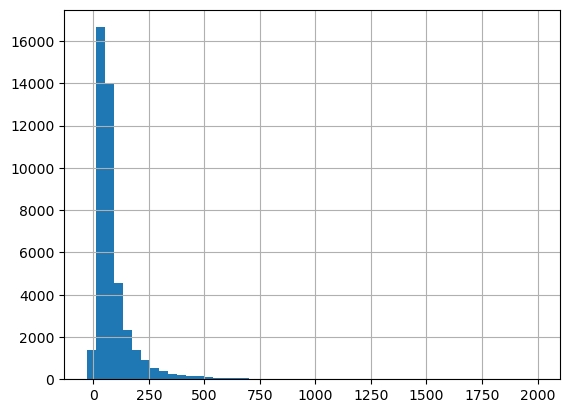

In [68]:
df_dates["processing_time_days"].hist(bins=50)

This histogram confirms that the distribution of application processing times is strongly right-skewed. 

Investigate zero-day processing times

In [69]:
(df_dates["processing_time_days"] == 0).sum()

np.int64(19)

In [70]:
df.loc[
   df_dates["processing_time_days"] == 0,
   ["application_reference_no", "application_type", "submission_date", "date_of_decision"]
]

,application_reference_no,application_type,submission_date,date_of_decision
9672,DAC2105678DC,disability_access_certificate_application_dac,2021-09-28,2021-09-28
10439,DAC2200927MH,disability_access_certificate_application_dac,2022-02-23,2022-02-23
12423,DAC2622373WD,disability_access_certificate_application_dac,2026-06-30,2026-06-30
15246,DAC2404946OY,disability_access_certificate_application_dac,2024-07-17,2024-07-17
17103,XDS2307394MH,dispensations,2023-11-22,2023-11-22
24063,FSC2516126MN,fire_safety_certificate_application_fsc,2025-10-16,2025-10-16
26564,FSC2301942MN/7DN,fire_safety_certificate_application_fsc,2023-04-06,2023-04-06
29667,FSC2202981LL/7DN,fire_safety_certificate_application_fsc,2022-06-13,2022-06-13
32572,FSC2200447OY,fire_safety_certificate_application_fsc,2022-02-01,2022-02-01
33563,FSC2404755OY,fire_safety_certificate_application_fsc,2024-07-10,2024-07-10


## Missing Data Analysis

The missing-value analysis revealed that some variables have substantial missingness. The BCMS supporting documentation indicates that certain fields are only applicable to particular application types or categories of work. For example, reason_for_revised_application is intended for revised FSC and DAC applications. Therefore, missing values may be structural rather than necessarily indicating data-quality errors.

In [71]:
missing_values = df.isna().sum()

print(missing_values.sort_values(ascending=False).to_string())


date_of_appeal                                              43564
decision_by_an_bord_pleanala                                43494
appeal_type                                                 43492
reason_for_revised_application                              43174
address_line_2                                              43130
is_the_building_still_under_construction                    43115
requirements_of_building_regulations_to_be_expanded_upon    43008
has_the_work_already_been_carried_out                       43006
grounds_for_the_application                                 43006
planning_permission_sought_modification                     42987
date_of_completion                                          42147
date_construction_started                                   41677
is_the_building_occupied_or_operational                     41667
is_construction_of_building_complete                        41667
has_modifications_during_construction                       41667
floor_area

Number of missing values in each of orginal 64 columns.

In [72]:
df.groupby("application_type")["reason_for_revised_application"].apply(
    lambda x: x.isna().sum()
)

application_type
disability_access_certificate_application_dac    16648
dispensations                                      512
fire_safety_certificate_application_fsc          20244
regularisation_certificate_application_fsc_rg     1953
relaxations                                        101
revised_disability_access_certificate_dac_rv      1287
revised_fire_safety_certificate_fsc_rv            2429
Name: reason_for_revised_application, dtype: int64

Counts missing values for the column "reason for revised application" within each application type. This variable was chosen because it's name sugguests that it may be specifically relevant to revised applications. 



In [73]:
df.groupby("application_type")["floor_area_of_building"].apply(
    lambda x: x.isna().sum()
)

application_type
disability_access_certificate_application_dac      0
dispensations                                    512
fire_safety_certificate_application_fsc          494
regularisation_certificate_application_fsc_rg    265
relaxations                                      101
revised_disability_access_certificate_dac_rv       0
revised_fire_safety_certificate_fsc_rv             0
Name: floor_area_of_building, dtype: int64

All 512 dispensation records and all 101 relaxation records are missing floor area, whereas the DAC and revised certificate categories have no missing values for this variable.
This suggests that missingness may be related to application type.


## Feature Selection and Data Leakage Assessment

In [74]:
for column in df.columns:
    print(column)

application_reference_no
application_type
local_authority
submission_no
submission_date
date_permission_was_granted
planning_permission_reference_no
seven_days_submission_no
classification_of_works_or_building
development_description
description_of_changes_from_original_application
location_of_the_proposed_development
eircode
street
address_line_2
town
county
LAT
LONGITUDE
related_fsc_application
use_of_proposed_works_or_building
sub_group
existing_use_of_building
main_construction_type
site_area
no_of_basement_stories
no_of_basement_stories_original
no_of_stories_above_ground_level
no_of_stories_above_ground_level_original
height_of_top_floor_above_ground_level
height_top_floor_above_ground_level_original
floor_area_of_building
floor_area_of_building_original
total_area_of_ground_floor
total_area_of_ground_floor_original
total_area_of_material_change_of_use
total_area_of_existing_building
floor_area_of_building_extension
total_combined_floor_area
floor_area_of_material_alteration
reas

We must not use information that becomes available only after submission, because that would introduce data leakage. 
Feature selection was considered based on whether each variable would be available at the time an application is submitted. Variables containing decision or appeal outcomes were identified as potential sources of data leakage and excluded from consideration as predictors. Application identifiers and personal information were also excluded from the proposed feature set. Building characteristics, application type, local authority and submission timing were identified as potential predictors, subject to further assessment of their completeness and applicability.

In [75]:
candidate_features = [
    "application_type",
    "local_authority",
    "submission_date",
    "classification_of_works_or_building",
    "use_of_proposed_works_or_building",
    "sub_group",
    "main_construction_type",
    "site_area",
    "floor_area_of_building",
    "total_area_of_ground_floor",
    "no_of_stories_above_ground_level",
    "no_of_basement_stories",
    "height_of_top_floor_above_ground_level"
]

In [76]:
df[candidate_features].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43619 entries, 0 to 43618
Data columns (total 13 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   application_type                        43619 non-null  object 
 1   local_authority                         43619 non-null  object 
 2   submission_date                         43619 non-null  object 
 3   classification_of_works_or_building     43619 non-null  object 
 4   use_of_proposed_works_or_building       43619 non-null  object 
 5   sub_group                               43101 non-null  object 
 6   main_construction_type                  41559 non-null  object 
 7   site_area                               43006 non-null  float64
 8   floor_area_of_building                  42247 non-null  float64
 9   total_area_of_ground_floor              41874 non-null  float64
 10  no_of_stories_above_ground_level        43006 non-null  fl

In [77]:
df[candidate_features].isna().sum().sort_values(ascending=False)

main_construction_type                    2060
total_area_of_ground_floor                1745
floor_area_of_building                    1372
site_area                                  613
no_of_basement_stories                     613
height_of_top_floor_above_ground_level     613
no_of_stories_above_ground_level           613
sub_group                                  518
use_of_proposed_works_or_building            0
application_type                             0
classification_of_works_or_building          0
submission_date                              0
local_authority                              0
dtype: int64

### Numerical Predictor Validation

In [78]:
df[candidate_features].describe()

,site_area,floor_area_of_building,total_area_of_ground_floor,no_of_stories_above_ground_level,no_of_basement_stories,height_of_top_floor_above_ground_level
count,4.300600e+04,4.224700e+04,4.187400e+04,43006.000000,43006.000000,43006.000000
mean,2.601651e+07,1.662408e+05,1.658295e+05,5.363438,0.249175,81.134165
std,1.953021e+09,3.355591e+07,3.370500e+07,338.928381,28.392404,1114.001175
min,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,-3.100000
25%,8.810000e+02,1.807550e+02,1.153500e+02,1.000000,0.000000,0.180000
50%,5.499900e+03,4.940000e+02,2.880000e+02,2.000000,0.000000,3.400000
75%,2.225553e+04,1.732000e+03,8.505000e+02,3.000000,0.000000,6.450000
max,1.841915e+11,6.897102e+09,6.897102e+09,50000.000000,5887.000000,59225.000000


In [79]:
numerical_features = [
    "site_area",
    "floor_area_of_building",
    "total_area_of_ground_floor",
    "no_of_stories_above_ground_level",
    "no_of_basement_stories",
    "height_of_top_floor_above_ground_level"
]

(df[numerical_features] < 0).sum()

site_area                                 0
floor_area_of_building                    0
total_area_of_ground_floor                0
no_of_stories_above_ground_level          3
no_of_basement_stories                    3
height_of_top_floor_above_ground_level    6
dtype: int64

Initial summary statistics revealed negative values in three numerical variables and extremely large maximum values across several building measurements. These findings suggest potential data-quality issues, including possible recording errors or special missing-value codes. Further investigation is required before deciding how to handle these observations during preprocessing.

In [80]:
negative_rows = (df[numerical_features] < 0).any(axis=1)

df.loc[
    negative_rows,
    ["application_reference_no", "application_type"] + numerical_features
]

,application_reference_no,application_type,site_area,floor_area_of_building,total_area_of_ground_floor,no_of_stories_above_ground_level,no_of_basement_stories,height_of_top_floor_above_ground_level
10084,DAC2107243DC,disability_access_certificate_application_dac,595.0,719.1,390.5,-1.0,-1.0,4.38
19392,FSC2516847DC/7DN,fire_safety_certificate_application_fsc,4164.0,142.1,142.1,1.0,0.0,-0.34
30539,FSC2204935CY,fire_safety_certificate_application_fsc,26387.0,50.9,50.9,1.0,0.0,-1.40
30552,FSC2204937CY,fire_safety_certificate_application_fsc,26387.0,77.7,77.7,1.0,0.0,-3.10
30554,FSC2204936CY,fire_safety_certificate_application_fsc,26387.0,157.2,157.2,1.0,0.0,-2.40
30566,FSC2204942CY,fire_safety_certificate_application_fsc,26387.0,36.3,36.3,1.0,0.0,-0.70
30586,FSC2204939CY,fire_safety_certificate_application_fsc,26387.0,36.3,36.3,1.0,0.0,-1.55
34976,FSC2103823DC,fire_safety_certificate_application_fsc,595.0,719.1,390.5,-1.0,-1.0,4.38
39711,DRV2306735DC,revised_disability_access_certificate_dac_rv,595.0,595.0,390.5,-1.0,-1.0,4.38


Numerical summary statistics revealed negative values in three building-related variables. Further investigation identified nine affected observations containing 12 negative entries: three negative above-ground storey counts, three negative basement storey counts and six negative top-floor heights. The three observations with negative storey counts shared similar building measurements, suggesting a possible relationship or common recording convention. As the meaning of these negative values could not be confirmed, they were flagged for further investigation rather than immediately removed or corrected.

In [81]:
for column in numerical_features:
    print("\n", column)
    print(
        df.loc[
            df[column] == df[column].max(),
            ["application_reference_no", column]
        ]
    )


 site_area
      application_reference_no     site_area
12983             DAC2103374DC  1.841915e+11
33153         FSC2102855DC/7DN  1.841915e+11
38960             FRG2404020DC  1.841915e+11

 floor_area_of_building
     application_reference_no  floor_area_of_building
7988             DAC2307089SO            6.897102e+09

 total_area_of_ground_floor
     application_reference_no  total_area_of_ground_floor
7988             DAC2307089SO                6.897102e+09

 no_of_stories_above_ground_level
     application_reference_no  no_of_stories_above_ground_level
1433             DAC2303647CC                           50000.0

 no_of_basement_stories
    application_reference_no  no_of_basement_stories
654             DAC2301551KE                  5887.0

 height_of_top_floor_above_ground_level
     application_reference_no  height_of_top_floor_above_ground_level
2116             DAC2000747DR                                 59225.0


Application references associated with the maximum value of each numerical predictor